In [12]:
#@title Menghubungkan Google Drive

from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
#@title Import library

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Library berhasil diimport.")

Library berhasil diimport.


In [14]:
#@title Mengambil data dari Colab pertama

# Lokasi file yang disimpan dari notebook pertama
ARTIFACT_PATH = (
    '/content/drive/MyDrive/hoax_project/'
    'artifacts/hoax_dataset_prepared.joblib'
)

# Memeriksa keberadaan file
if not os.path.exists(ARTIFACT_PATH):
    raise FileNotFoundError(
        "File preprocessing tidak ditemukan. "
        "Jalankan export pada notebook pertama terlebih dahulu."
    )

# Membaca file hasil preprocessing
artifacts = joblib.load(ARTIFACT_PATH)

# Mengambil masing-masing variabel
X_train = artifacts['X_train']
X_val = artifacts['X_val']
X_test = artifacts['X_test']

y_train = artifacts['y_train']
y_val = artifacts['y_val']
y_test = artifacts['y_test']

x_train_tfidf = artifacts['x_train_tfidf']
x_val_tfidf = artifacts['x_val_tfidf']
x_test_tfidf = artifacts['x_test_tfidf']

tfidf = artifacts['tfidf']

print("Data berhasil dihubungkan dari notebook pertama!")

Data berhasil dihubungkan dari notebook pertama!


In [15]:
#@title Memastikan data sudah terhubung

print("Jumlah Data:")

print("Training  :", len(X_train))
print("Validation:", len(X_val))
print("Testing   :", len(X_test))

print("\nShape TF-IDF:")

print("Training  :", x_train_tfidf.shape)
print("Validation:", x_val_tfidf.shape)
print("Testing   :", x_test_tfidf.shape)

print("\nDistribusi kelas Training:")
print(y_train.value_counts())

print("\nDistribusi kelas Validation:")
print(y_val.value_counts())

Jumlah Data:
Training  : 21897
Validation: 4692
Testing   : 4693

Shape TF-IDF:
Training  : (21897, 20000)
Validation: (4692, 20000)
Testing   : (4693, 20000)

Distribusi kelas Training:
hoax
0    14658
1     7239
Name: count, dtype: int64

Distribusi kelas Validation:
hoax
0    3141
1    1551
Name: count, dtype: int64


In [16]:
#@title Membuat model

nb_model = MultinomialNB(
    alpha=1.0,
    fit_prior=True
)

print("Multinomial Naive Bayes berhasil dibuat.")

Multinomial Naive Bayes berhasil dibuat.


In [17]:
#@title Training

start_time = time.perf_counter()

nb_model.fit(
    x_train_tfidf,
    y_train
)

end_time = time.perf_counter()

training_time_nb = end_time - start_time

print("Training selesai!")

print("Jumlah fitur:", nb_model.n_features_in_)
print("Jumlah kelas:", nb_model.classes_)

print(
    f"Training Time: {training_time_nb:.4f} detik"
)

Training selesai!
Jumlah fitur: 20000
Jumlah kelas: [0 1]
Training Time: 0.0115 detik


In [18]:
#@title Prediksi validation

y_val_pred_nb = nb_model.predict(
    x_val_tfidf
)

akurasi_nb = accuracy_score(
    y_val,
    y_val_pred_nb
)

print("Accuracy Validation:", akurasi_nb)
print(
    f"Accuracy: {akurasi_nb * 100:.2f}%"
)


Accuracy Validation: 0.9396845694799659
Accuracy: 93.97%


In [19]:
#@title Classification Report

print("Classification Report - Naive Bayes")

print(
    classification_report(
        y_val,
        y_val_pred_nb,
        labels=[0, 1],
        target_names=['Non-Hoaks', 'Hoaks'],
        digits=4,
        zero_division=0
    )
)

Classification Report - Naive Bayes
              precision    recall  f1-score   support

   Non-Hoaks     0.9304    0.9834    0.9562      3141
       Hoaks     0.9621    0.8511    0.9032      1551

    accuracy                         0.9397      4692
   macro avg     0.9463    0.9173    0.9297      4692
weighted avg     0.9409    0.9397    0.9387      4692



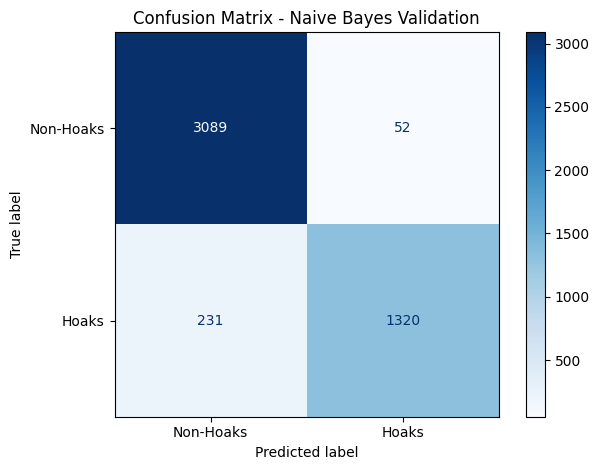

In [20]:
#@title Confusion Matrix
cm_nb = confusion_matrix(
    y_val,
    y_val_pred_nb,
    labels=[0, 1]
)

disp_nb = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=['Non-Hoaks', 'Hoaks']
)

disp_nb.plot(
    cmap='Blues',
    values_format='d'
)

plt.title(
    'Confusion Matrix - Naive Bayes Validation'
)

plt.tight_layout()
plt.show()


In [21]:
#@title Save Model Baseline

import os
import joblib

# Membuat folder penyimpanan
SAVE_DIR = '/content/drive/MyDrive/hoax_project/models'
os.makedirs(SAVE_DIR, exist_ok=True)

# Lokasi penyimpanan model
MODEL_PATH = os.path.join(
    SAVE_DIR,
    'multinomial_naive_bayes_baseline.joblib'
)

# Menyimpan model
joblib.dump(nb_model, MODEL_PATH)

print("Model baseline berhasil disimpan!")
print("Lokasi:", MODEL_PATH)

Model baseline berhasil disimpan!
Lokasi: /content/drive/MyDrive/hoax_project/models/multinomial_naive_bayes_baseline.joblib


In [22]:
#@title Menguji penyimpanan model

# Memuat kembali model yang telah disimpan
nb_model_loaded = joblib.load(MODEL_PATH)

# Menguji prediksi menggunakan model hasil load
y_val_pred_loaded = nb_model_loaded.predict(x_val_tfidf)

# Memeriksa kesamaan hasil prediksi
if np.array_equal(y_val_pred_nb, y_val_pred_loaded):
    print("Model berhasil disimpan dan dimuat kembali!")
    print("Hasil prediksi tetap sama.")
else:
    print("Terdapat perbedaan hasil prediksi.")

Model berhasil disimpan dan dimuat kembali!
Hasil prediksi tetap sama.


In [23]:
#@title Membuat tabel perbandingan

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Menghitung metrik Naive Bayes
nb_accuracy = accuracy_score(y_val, y_val_pred_nb)

nb_precision = precision_score(
    y_val,
    y_val_pred_nb,
    pos_label=1
)

nb_recall = recall_score(
    y_val,
    y_val_pred_nb,
    pos_label=1
)

nb_f1 = f1_score(
    y_val,
    y_val_pred_nb,
    pos_label=1
)

# Hasil SVM dari notebook utama (validation set)
svm_accuracy = 0.957587
svm_precision = 0.949468
svm_recall = 0.920696
svm_f1 = 0.934861

# Membuat tabel perbandingan
comparison = pd.DataFrame({
    'Model': [
        'Multinomial Naive Bayes',
        'Linear SVM'
    ],
    'Accuracy': [
        nb_accuracy,
        svm_accuracy
    ],
    'Precision Hoaks': [
        nb_precision,
        svm_precision
    ],
    'Recall Hoaks': [
        nb_recall,
        svm_recall
    ],
    'F1-Score Hoaks': [
        nb_f1,
        svm_f1
    ]
})

print("PERBANDINGAN BASELINE DAN ADVANCED MODEL")
display(
    comparison.style.format({
        'Accuracy': '{:.4f}',
        'Precision Hoaks': '{:.4f}',
        'Recall Hoaks': '{:.4f}',
        'F1-Score Hoaks': '{:.4f}'
    })
)

PERBANDINGAN BASELINE DAN ADVANCED MODEL


,Model,Accuracy,Precision Hoaks,Recall Hoaks,F1-Score Hoaks
0,Multinomial Naive Bayes,0.9397,0.9621,0.8511,0.9032
1,Linear SVM,0.9576,0.9495,0.9207,0.9349


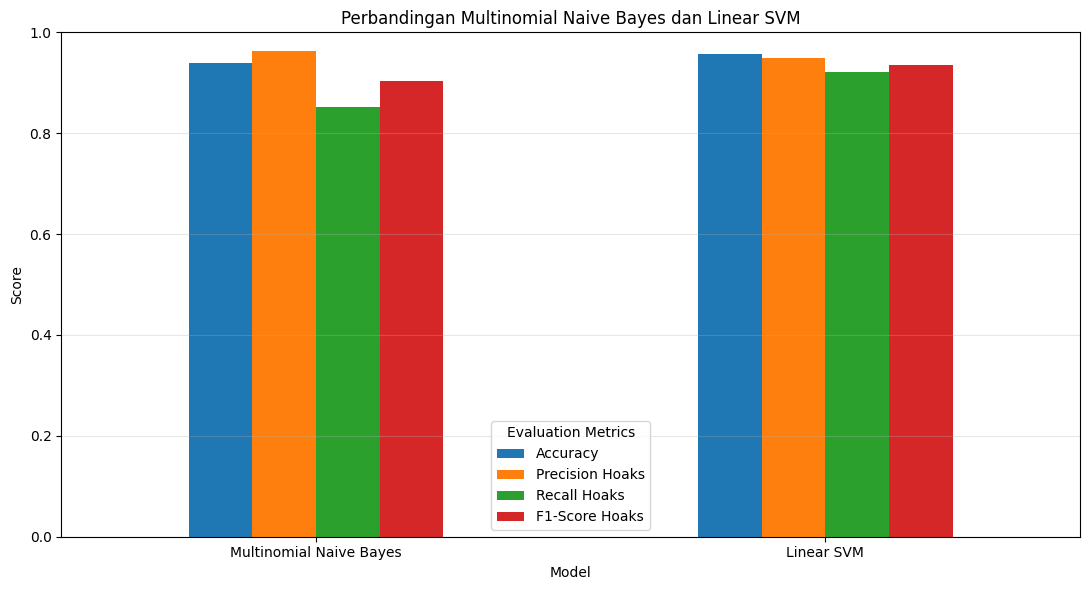

In [24]:
#@title Visualisasi perbandingan
# Mengatur metrik yang akan dibandingkan
metrics = [
    'Accuracy',
    'Precision Hoaks',
    'Recall Hoaks',
    'F1-Score Hoaks'
]

# Membuat grafik
comparison_plot = comparison.set_index('Model')[metrics]

comparison_plot.plot(
    kind='bar',
    figsize=(11, 6),
    ylim=(0, 1),
    rot=0
)

plt.title('Perbandingan Multinomial Naive Bayes dan Linear SVM')
plt.ylabel('Score')
plt.xlabel('Model')
plt.legend(title='Evaluation Metrics')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()